In [1]:
from sklearn.datasets import make_classification 
import numpy as np 
X,y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=20)

In [2]:
import matplotlib.pyplot as plt 

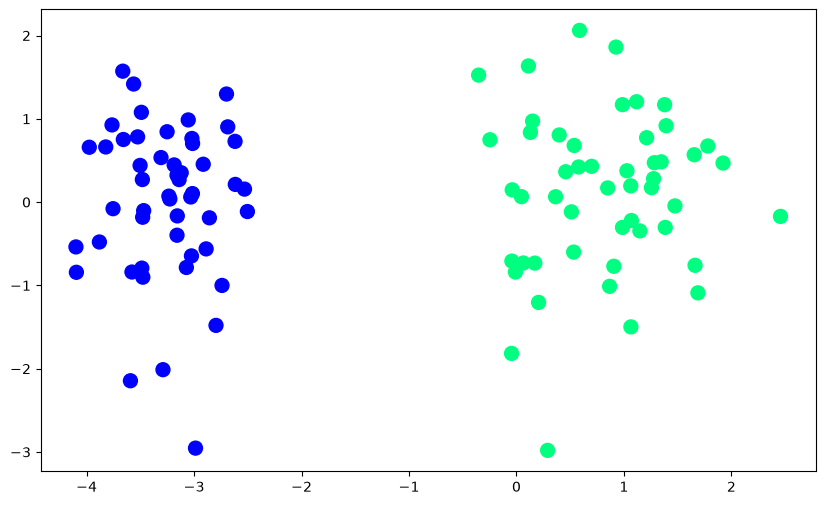

In [3]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [4]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression(penalty=None,solver='sag')
lor.fit(X,y)

C:\Users\divya\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\divya\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'sag'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may no

In [5]:
print(lor.coef_)
print(lor.intercept_)

[[4.84663113 0.22541667]]
[5.81710449]


In [6]:
m1 = -(lor.coef_[0][0]/lor.coef_[0][1])
b1 = -(lor.intercept_/lor.coef_[0][1])

In [7]:
x_input = np.linspace(-3,3,100)
y_input = m1*x_input + b1

In [8]:
def gd(X,y):
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.5
    
    for i in range(2500):
        y_hat = sigmoid(np.dot(X,weights))
        weights = weights + lr*(np.dot((y-y_hat),X)/X.shape[0])
        
    return weights[1:],weights[0]
        

In [9]:
X1 = np.insert(X,0,1,axis=1)
np.ones(X1.shape[1])

array([1., 1., 1.])

In [10]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

In [11]:
coef_,intercept_ = gd(X,y)

In [12]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [13]:
x_input1 = np.linspace(-3,3,100)
y_input1 = m*x_input1 + b

(-3.0, 2.0)

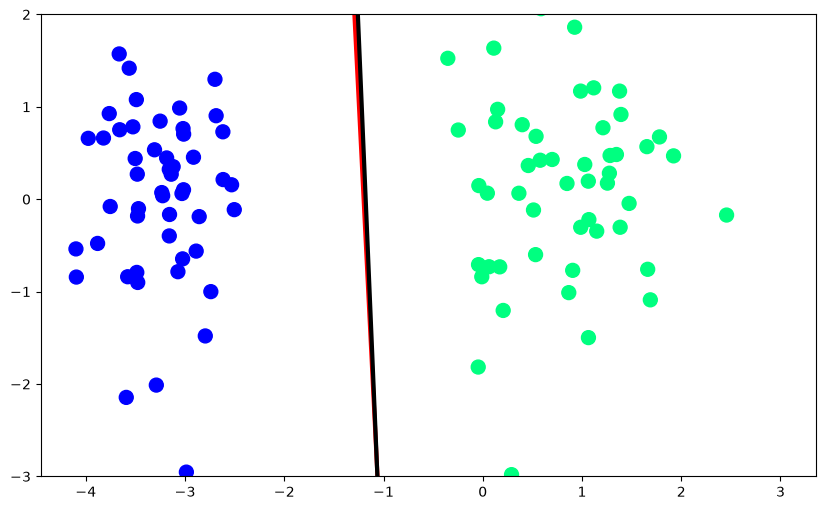

In [14]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3) # Sklearn's LR Model implementation
plt.plot(x_input1,y_input1,color='black',linewidth=3)  # our LR Model 
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)


## Reason of this difference may be the epoch 
### so we willl try increasing the epoch 

In [15]:
def gd(X,y):
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.5
    
    for i in range(5000):
        y_hat = sigmoid(np.dot(X,weights))
        weights = weights + lr*(np.dot((y-y_hat),X)/X.shape[0])
        
    return weights[1:],weights[0]

In [16]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

In [17]:
coef_,intercept_ = gd(X,y)

In [18]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])
x_input1 = np.linspace(-3,3,100)
y_input1 = m*x_input1 + b

(-3.0, 2.0)

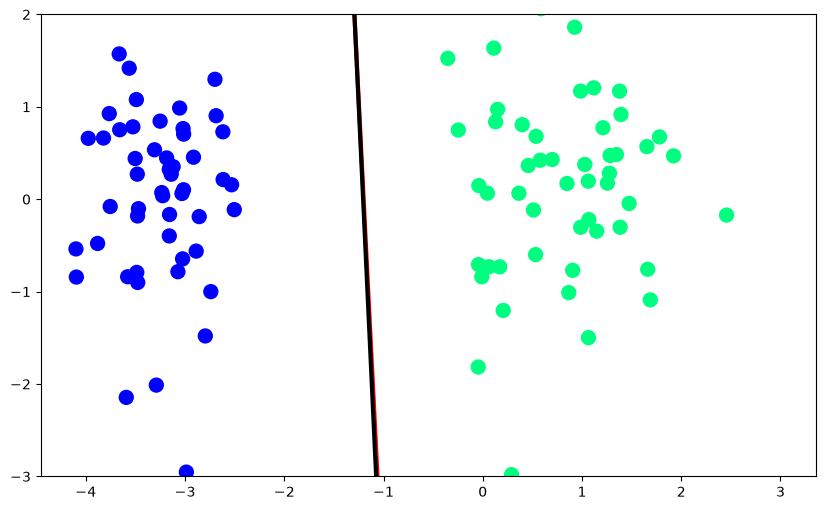

In [19]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

### what is penalty and solver parameters in logistic regression
<b>In logistic regression (such as in Python's scikit-learn LogisticRegression), the penalty and solver parameters control how the model prevents overfitting and how it finds the best mathematical solution.

**1. Penalty (Regularization)**
<p class="preserved-bold-text">
The penalty parameter specifies the type of regularization applied to the loss function. Regularization prevents the model from becoming too complex or overfitting the training data by adding a penalty for large coefficient weights.

• 'l2' (Ridge Regularization): The default option. It shrinks the coefficients smoothly toward zero without making them exactly zero. It works well when most features are useful.

• 'l1' (Lasso Regularization): It can shrink some coefficients down to zero. This acts as automatic feature selection by dropping unimportant features.

• 'elasticnet': A mix of both L1 and L2 penalties. It requires an extra parameter, l1_ratio, to balance between them.

• None: No regularization is applied. The model purely minimizes the log loss.</b></p>



**2. Solver (Optimization Algorithm)**
<p class="preserved-bold-text">
The solver parameter specifies the mathematical algorithm used to optimize and find the best weights (coefficients) for the logistic regression cost function. Different solvers handle different types of penalties and dataset sizes:
    
• 'lbfgs' (Limited-memory BFGS): The default solver in modern scikit-learn. It uses a quasi-Newton method approximation, works well for multi-class classification, and supports L2 or no penalty. It does not support L1.
    
• 'liblinear': Uses a coordinate descent algorithm. It is a good choice for smaller datasets and supports both L1 and L2 penalties.

• 'newton-cg': Uses a second-order Newton-conjugate gradient method. It is accurate and works well for small feature sets with L2 or no penalty, though it can be slow on large datasets.

• 'newton-cholesky': Uses a Newton method with a Cholesky decomposition. It is fast when the number of samples is much larger than the number of features.

• 'sag' (Stochastic Average Gradient descent): Designed for large-scale datasets. It is faster on big data, supporting L2 or no penalty.

• 'saga': An extension of SAG that supports L1, L2, and ElasticNet regularization. It is the best choice for very large datasets when you need L1 regularization.
</p>

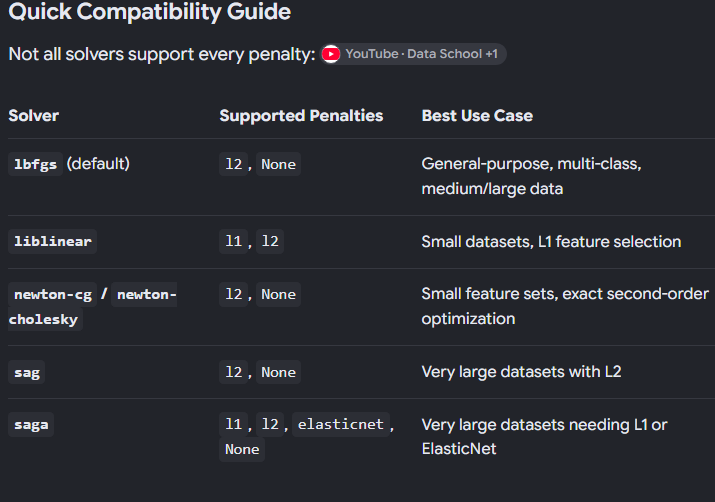

<div style="background-color: #f1f5f9; border-left: 5px solid #64748b; padding: 12px; margin-bottom: 20px; font-family: Arial, sans-serif;">
<p style="margin: 0; font-style: italic; color: #334155; font-weight: bold;">
What is the meaning and significance of solvers and penalty??? Also, for any sklearn function is same irrespective of the class applied or it varies ?? both the parametres range of values vary right ??
</p>
</div>

<div style="background-color: #e0f2fe; border-left: 5px solid #0284c7; padding: 15px; margin-bottom: 20px; font-family: Arial, sans-serif;">
<p style="margin: 0; font-size: 1.1em; color: #0369a1; font-weight: bold;">
The high-level meaning and significance of solver and penalty remain the same across machine learning, but their exact values, options, and behaviors vary heavily depending on the specific sklearn class you use.
</p>
<p style="margin: 10px 0 0 0; color: #0c4a6e;">
You cannot copy-paste the exact same solver strings or penalty arguments from one sklearn class to another; they change based on the underlying math of the model.
</p>
</div>

# 1. The Core Meaning & Significance

No matter which sklearn class you are using, the high-level purpose of these two concepts never changes:

<div style="background-color: #fffbeb; border-left: 5px solid #d97706; padding: 12px; margin-bottom: 15px; border-radius: 4px; font-family: Arial, sans-serif;">
<b style="color: #b45309;">• penalty (Regularization):</b> Its significance is to prevent overfitting and improve how the model performs on unseen data. It acts like a "complexity tax" that penalizes the model for relying too heavily on any single feature or for using too many features. It forces the model to stay simple, smooth, and generalized.
</div>

<div style="background-color: #f0fdf4; border-left: 5px solid #16a34a; padding: 12px; margin-bottom: 25px; border-radius: 4px; font-family: Arial, sans-serif;">
<b style="color: #15803d;">• solver (Optimization Algorithm):</b> Its significance is to solve the math problem. A machine learning model defines a "loss function" (a mathematical formula measuring how wrong the model's guesses are). The solver is the engine or calculator that runs behind the scenes to find the exact weights and coefficients that minimize that loss.
</div>

# 2. Do the Range of Values Vary Across Classes? (Yes!)

**Yes, the acceptable range of values changes completely because different models solve entirely different mathematical problems.**

<div style="background-color: #f8fafc; border: 1px solid #e2e8f0; border-radius: 6px; padding: 12px; margin-bottom: 15px; font-family: Arial, sans-serif;">
<b style="color: #0284c7; display: block; margin-bottom: 5px;">⚙️ How solver values vary:</b>
<span style="color: #475569; font-style: italic; display: block; margin-bottom: 8px;">
A solver that minimizes classification errors cannot be used to minimize clustering distances or continuous regression lines.
</span>
* In **LogisticRegression**, the solver values are algorithms like 'lbfgs', 'liblinear', or 'saga'.
* In **Ridge** (Linear Regression), the solver values change to algorithms like 'svd', 'cholesky', or 'lsqr'.
* In **LinearRegression** or **KMeans**, there is no solver parameter at all because the optimization technique is hardcoded into the architecture of the class itself.
</div>

<div style="background-color: #f8fafc; border: 1px solid #e2e8f0; border-radius: 6px; padding: 12px; font-family: Arial, sans-serif;">
<b style="color: #d97706; display: block; margin-bottom: 5px;">🛡️ How penalty values vary:</b>
<span style="color: #475569; font-style: italic; display: block; margin-bottom: 8px;">
Even the way you declare a penalty changes depending on the class:
</span>
* In **LogisticRegression** and **SGDClassifier**, it is a string parameter named penalty (e.g., penalty='l1' or penalty='l2').
* In standard linear models, sklearn splits the penalties into entirely separate classes instead of a parameter. If you want a linear regression with an L2 penalty, you must import **Ridge**. If you want an L1 penalty, you must import **Lasso**.
* The strength parameter changes names too. In **LogisticRegression**, the penalty strength is controlled by **C** (where smaller means stronger regularization). In **Ridge** and **Lasso**, the penalty strength is controlled by **alpha** (where larger means stronger regularization).
</div>


In [ ]:
# Saving vaia Numpy Binary file 

In [20]:
import numpy as np

# 1. Run your model and capture the output arrays
final_coef, final_weights = gd(X, y)

# 2. Save the array containing all parameters to a local file
np.save('logistic_regression_weights.npy', final_weights)

print("Weights successfully saved!")


Weights successfully saved!


In [21]:
## To load these exact parameters back into memory later (or in a separate notebook) without retraining:

In [ ]:
# Load the weights back instantly
loaded_weights = np.load('logistic_regression_weights.npy')


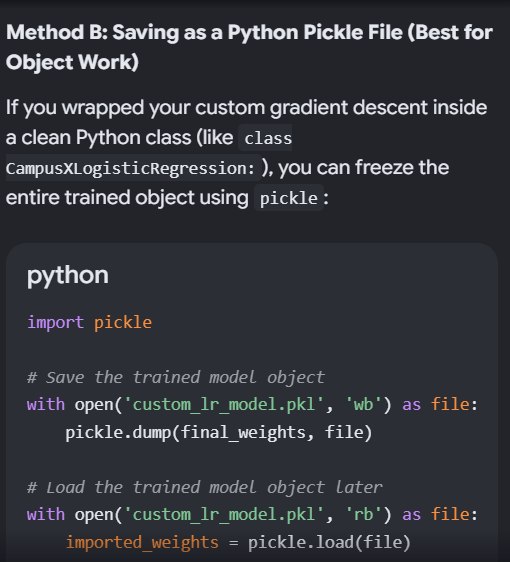

In [ ]:
import pickle

# Save the trained model object
with open('custom_lr_model.pkl', 'wb') as file:
    pickle.dump(final_weights, file)

# Load the trained model object later
with open('custom_lr_model.pkl', 'rb') as file:
    imported_weights = pickle.load(file)
